In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [29]:
import pandas as pd
df = pd.read_csv("CLASS_RESULT_PROJECT_DATASET.csv")
df.head()

,S.No,STUDENT NAME,ROLL NO,Gender,SPI - 1st Sem,SPI - 2nd Sem,SPI - 3rd Sem,SPI - 4th Sem,SPI - 5th Sem,SPI - 6th Sem,Attendance,Stay
0,1,Aarti Suryvanshi,23113001,Female,5.95,7.25,6.69,7.26,7.66,7.60,85,Day Scholar
1,2,Aaryan lahre,23113002,Male,6.30,6.80,NaN,NaN,NaN,NaN,40,Day Scholar
2,3,Aaryansh Dwivedi,23113003,Male,7.70,7.50,6.60,6.50,7.23,6.56,76,Day Scholar
3,4,Aayushman Dash,23113004,Male,8.50,9.20,8.19,9.15,8.19,8.78,89,Hosteller
4,5,Abhinav Anand,23113006,Male,8.33,8.75,8.00,NaN,7.23,7.52,71,Hosteller


In [30]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['S.No', 'STUDENT NAME', 'ROLL NO', 'Gender', 'SPI - 1st Sem', 'SPI - 2nd Sem', 'SPI - 3rd Sem', 'SPI - 4th Sem', 'SPI - 5th Sem', 'SPI - 6th Sem', 'Attendance', 'Stay']


In [31]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   S.No           69 non-null     int64  
 1   STUDENT NAME   69 non-null     str    
 2   ROLL NO        69 non-null     int64  
 3   Gender         69 non-null     str    
 4   SPI - 1st Sem  68 non-null     float64
 5   SPI - 2nd Sem  69 non-null     float64
 6   SPI - 3rd Sem  66 non-null     float64
 7   SPI - 4th Sem  56 non-null     float64
 8   SPI - 5th Sem  63 non-null     float64
 9   SPI - 6th Sem  63 non-null     float64
 10  Attendance     69 non-null     int64  
 11  Stay           69 non-null     str    
dtypes: float64(6), int64(3), str(3)
memory usage: 6.6 KB


In [32]:
print("Missing Values:")
missing = df.isnull().sum()
print(missing)

Missing Values:
S.No              0
STUDENT NAME      0
ROLL NO           0
Gender            0
SPI - 1st Sem     1
SPI - 2nd Sem     0
SPI - 3rd Sem     3
SPI - 4th Sem    13
SPI - 5th Sem     6
SPI - 6th Sem     6
Attendance        0
Stay              0
dtype: int64


In [33]:
missing_data = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

missing_data = missing_data[missing_data["Missing Values"] > 0]
missing_data.sort_values("Missing Percentage", ascending=False)

,Missing Values,Missing Percentage
SPI - 4th Sem,13,18.84
SPI - 6th Sem,6,8.70
SPI - 5th Sem,6,8.70
SPI - 3rd Sem,3,4.35
SPI - 1st Sem,1,1.45


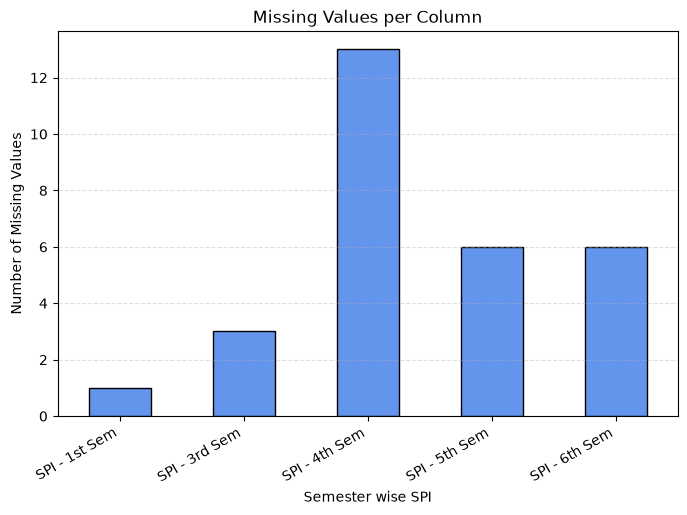

In [39]:
missing = missing[missing > 0]

plt.figure(figsize=(8, 5))
missing.plot(kind="bar", color="cornflowerblue", edgecolor="black")

plt.title("Missing Values per Column")
plt.xlabel("Semester wise SPI")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

## Data Preparation

The 6th-semester SPI will be used to define the target variable.
Students with missing 6th-semester SPI cannot be assigned a
target category and will be excluded from this classification task.

In [41]:
# Keep students whose 6th-semester SPI is available
data = df.dropna(subset=["SPI - 6th Sem"]).copy()

# Create performance categories
def classify_performance(spi):
    if spi < 5.0:
        return "Needs Improvement"
    elif spi < 7.0:
        return "Average"
    elif spi < 8.5:
        return "Good"
    else:
        return "Excellent"

data["Performance"] = data["SPI - 6th Sem"].apply(classify_performance)

print("Dataset shape:", data.shape)
print("\nPerformance category counts:")
print(data["Performance"].value_counts())

data[["SPI - 6th Sem", "Performance"]].head()

Dataset shape: (63, 13)

Performance category counts:
Performance
Good         44
Excellent    14
Average       5
Name: count, dtype: int64


,SPI - 6th Sem,Performance
0,7.60,Good
2,6.56,Average
3,8.78,Excellent
4,7.52,Good
5,8.26,Good


## Feature Selection

The first five semester's SPI, attendance, gender, and stay status
will be used as input features. The target variable is Performance.
Student names, roll numbers, serial numbers, and 6th-semester SPI
will not be used as input features.

In [42]:
features = [
    "Gender",
    "SPI - 1st Sem",
    "SPI - 2nd Sem",
    "SPI - 3rd Sem",
    "SPI - 4th Sem",
    "SPI - 5th Sem",
    "Attendance",
    "Stay"
]

X = data[features].copy()
y = data["Performance"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Features shape: (63, 8)
Target shape: (63,)


,Gender,SPI - 1st Sem,SPI - 2nd Sem,SPI - 3rd Sem,SPI - 4th Sem,SPI - 5th Sem,Attendance,Stay
0,Female,5.95,7.25,6.69,7.26,7.66,85,Day Scholar
2,Male,7.70,7.50,6.60,6.50,7.23,76,Day Scholar
3,Male,8.50,9.20,8.19,9.15,8.19,89,Hosteller
4,Male,8.33,8.75,8.00,NaN,7.23,71,Hosteller
5,Male,8.33,8.91,9.00,8.56,8.33,75,Hosteller
